In [37]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.datasets import fetch_california_housing


In [38]:
housing = fetch_california_housing(as_frame=True)

In [39]:
df = housing.frame

In [40]:
df.to_csv("/Users/amankumar/Desktop/ML_LEARNING/Dataset/california_housing.csv", index=False)

In [41]:
df.head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [42]:
df.shape

(20640, 9)

In [43]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [44]:
X=df.drop("MedHouseVal",axis=1)
y=df["MedHouseVal"]

In [45]:
from sklearn.model_selection import train_test_split

X_train , X_test, y_train , y_test = train_test_split(
    X,y ,test_size=0.2 , random_state=42
)

In [46]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import ElasticNet

model=make_pipeline(
    StandardScaler(),
    ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)
)

In [47]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('elasticnet', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [48]:
y_pred=model.predict(X_test)
print(y_pred[:10])

[1.1358095  1.61451454 2.18905062 2.6963687  2.14793234 2.2011591
 2.64388125 2.14497394 2.17206549 3.8675835 ]


In [49]:
from sklearn.metrics import mean_absolute_error , mean_squared_error , r2_score

print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  0.597040896308898
MSE :  0.6358566879910782
R2 :  0.5147647043408876


In [50]:
result=pd.DataFrame({
    "Actual ": y_test.values,
    "Predicted ": y_pred
})

print(result.head(10))

   Actual   Predicted 
0  0.47700    1.135810
1  0.45800    1.614515
2  5.00001    2.189051
3  2.18600    2.696369
4  2.78000    2.147932
5  1.58700    2.201159
6  1.98200    2.643881
7  1.57500    2.144974
8  3.40000    2.172065
9  4.46600    3.867584


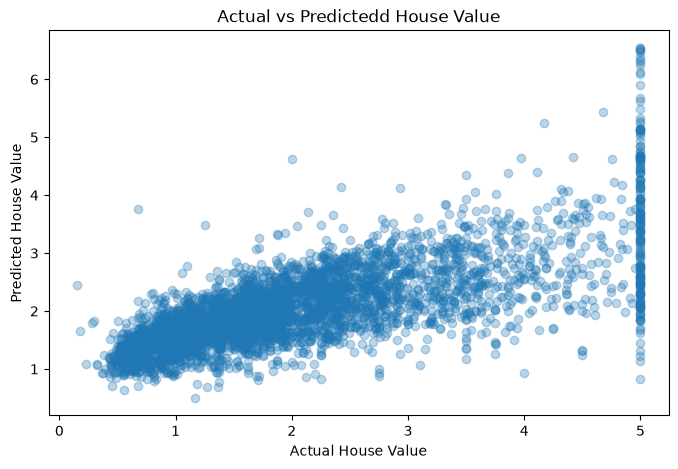

In [51]:
 
plt.figure(figsize=(8,5))

plt.scatter(y_test,y_pred,alpha=0.3)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Actual vs Predictedd House Value")
plt.show()

In [52]:
for alpha in [0.01,0.1,1,10]:
    for ratio in [0.2,0.5,0.8]:

        model=make_pipeline(
            StandardScaler(),
            ElasticNet(
                alpha=alpha,
                l1_ratio=ratio,
                max_iter=10000
            )
        )

        model.fit(X_train ,y_train)

        pred=model.predict(X_test)

        print(
            f"alpha={alpha}, l1_ratio{ratio},"
            f"R2={r2_score(y_test, pred):.4f}"
        )

alpha=0.01, l1_ratio0.2,R2=0.5792
alpha=0.01, l1_ratio0.5,R2=0.5803
alpha=0.01, l1_ratio0.8,R2=0.5812
alpha=0.1, l1_ratio0.2,R2=0.5411
alpha=0.1, l1_ratio0.5,R2=0.5148
alpha=0.1, l1_ratio0.8,R2=0.4873
alpha=1, l1_ratio0.2,R2=0.3064
alpha=1, l1_ratio0.5,R2=0.2031
alpha=1, l1_ratio0.8,R2=-0.0002
alpha=10, l1_ratio0.2,R2=-0.0002
alpha=10, l1_ratio0.5,R2=-0.0002
alpha=10, l1_ratio0.8,R2=-0.0002


In [53]:
from sklearn.model_selection import GridSearchCV

pipeline=make_pipeline(
    StandardScaler(),
    ElasticNet(max_iter=10000)
)

params={
     "elasticnet__alpha": [0.01, 0.1, 1, 10],
    "elasticnet__l1_ratio": [0.2, 0.5, 0.8]
}

grid=GridSearchCV(
    pipeline,
    params,
    cv=5,
    scoring="r2"
)
grid.fit(X_train,y_train)
print("Best Parameters : ",grid.best_params_)
print("Best CV R2 Scores : ",grid.best_score_)



Best Parameters :  {'elasticnet__alpha': 0.01, 'elasticnet__l1_ratio': 0.2}
Best CV R2 Scores :  0.6097795593352426


In [54]:
best_model=grid.best_estimator_
y_pred=best_model.predict(X_test)

print("Test R2 Score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))

Test R2 Score: 0.5792322144884947
MAE: 0.5335695068512357
MSE: 0.5513778838888177


In [55]:
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Elastic Net": ElasticNet(
        alpha=0.1,
        l1_ratio=0.5,
        max_iter=10000
    )
}

results = []

for name, algorithm in models.items():

    model = make_pipeline(
        StandardScaler(),
        algorithm
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

               Model  R2 Score     MAE     MSE
0  Linear Regression    0.5758  0.5332  0.5559
1              Ridge    0.5758  0.5332  0.5559
2              Lasso    0.4814  0.6222  0.6796
3        Elastic Net    0.5148  0.5970  0.6359


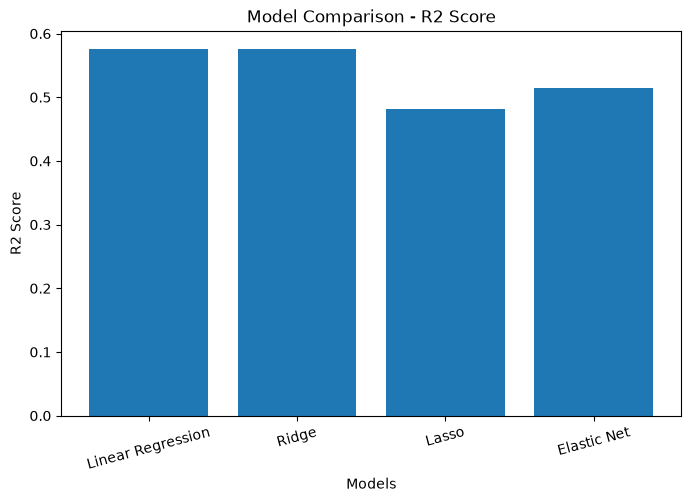

In [56]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["R2 Score"])
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.title("Model Comparison - R2 Score")
plt.xticks(rotation=15)
plt.show()

In [57]:

best_model = grid.best_estimator_


elastic_model = best_model.named_steps["elasticnet"]

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": elastic_model.coef_
})

coefficients["Abs_Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Abs_Coefficient",
    ascending=False
)

print(coefficients)

      Feature  Coefficient  Abs_Coefficient
0      MedInc     0.836105         0.836105
6    Latitude    -0.788556         0.788556
7   Longitude    -0.758773         0.758773
3   AveBedrms     0.283094         0.283094
2    AveRooms    -0.244445         0.244445
1    HouseAge     0.131747         0.131747
5    AveOccup    -0.039089         0.039089
4  Population     0.000000         0.000000


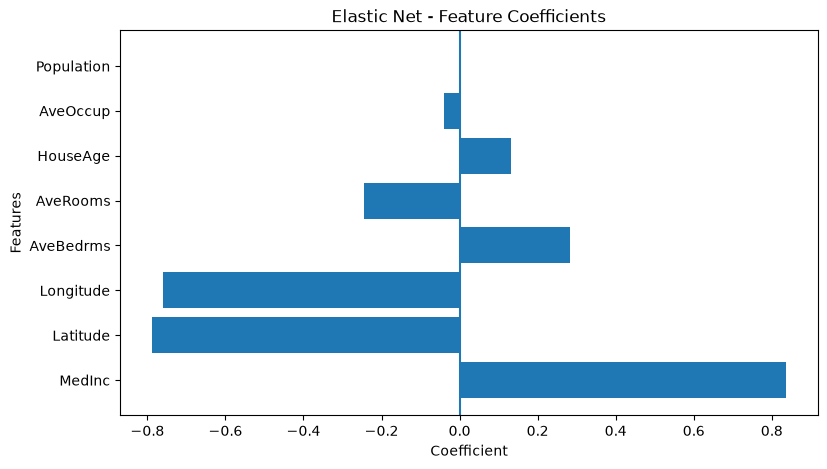

In [58]:
plt.figure(figsize=(9, 5))

plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Features")
plt.title("Elastic Net - Feature Coefficients")
plt.axvline(x=0)
plt.show()

In [59]:
new_house = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 30.0,
    "AveRooms": 5.0,
    "AveBedrms": 1.0,
    "Population": 1000.0,
    "AveOccup": 3.0,
    "Latitude": 34.0,
    "Longitude": -118.0
}])

predicted_value = best_model.predict(new_house)

print("Predicted House Value: $", round(predicted_value[0] * 100000, 2))

Predicted House Value: $ 256745.3


In [60]:
import joblib

joblib.dump(best_model, "elastic_net_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [61]:
residuals = y_test - y_pred

print("First 10 Residuals:")
print(residuals.head(10))

First 10 Residuals:
20046   -0.297115
3024    -1.280619
15663    2.360865
20484   -0.631019
9814     0.241099
13311   -0.448420
7113    -0.670075
7668    -0.593868
18246    0.760497
5723     0.538172
Name: MedHouseVal, dtype: float64


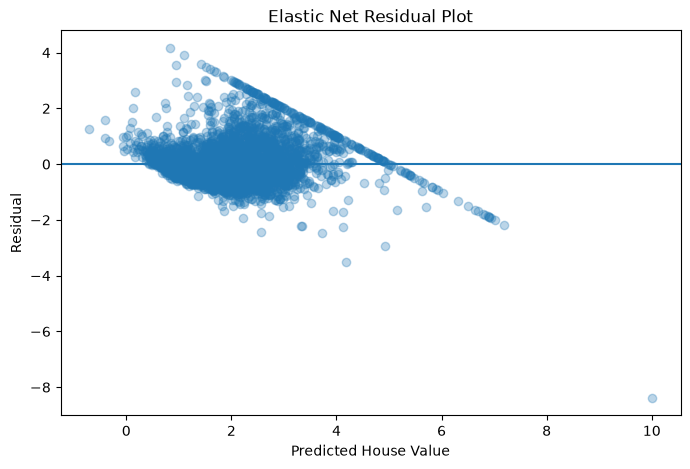

In [62]:

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0)
plt.xlabel("Predicted House Value")
plt.ylabel("Residual")
plt.title("Elastic Net Residual Plot")
plt.show()